# Prototipo de detección de carril para atletas con discapacidad visual — v2

**Proyecto PEEES 2026 · Independencia deportiva** · Becario: Miguel Isay Morales Cortés · Investigador responsable: Rafael Morales Gamboa

Ejecuta las celdas **en orden** (en Colab: *Entorno de ejecución → Ejecutar todas*). Todo funciona sin subir archivos; la última sección es opcional para probar tu propio video.

**Reproducibilidad:** el dataset se descarga en una versión fija (commit `aecdd7a`), las partes aleatorias usan semillas fijas y la primera celda muestra las versiones de las librerías. Con OpenCV 4.12 (Colab) y 5.0 los resultados con imágenes reales son idénticos; en el video artificial pueden variar ±1 punto porque el ruido simulado se genera ligeramente distinto.

| Sección | Qué hace | ¿Qué cambió respecto a la v1? |
|---|---|---|
| 1 | Detector de líneas (brillo → bordes → Hough) | Umbral de brillo **adaptativo** (una línea) |
| 2 | Prueba con video artificial **con respuestas conocidas** | Ahora se calcula el % de aciertos, con y sin vibración de cámara |
| 3 | Suavizado entre cuadros | **Nuevo**: promedio de los últimos cuadros para reducir parpadeos |
| 4 | Evaluación con imágenes reales anotadas (TrackAid-DT) | **Nuevo**: métricas reales contra el carril marcado a mano |
| 5 | Tu propio video (opcional) | Usa el suavizado y guarda un CSV por cuadro |

> Es una **estimación visual**, no una medición en metros. No sustituye a un guía.

In [1]:
# Librerías. En Colab ya vienen instaladas; si falta OpenCV, se instala.
try:
    import cv2
except ImportError:
    %pip install -q opencv-python-headless
    import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from pathlib import Path
import sys, matplotlib
print("Python:", sys.version.split()[0], "| OpenCV:", cv2.__version__, "| NumPy:", np.__version__,
      "| pandas:", pd.__version__, "| Matplotlib:", matplotlib.__version__)

def mostrar(imagenes, titulos, columnas=4, ancho=16):
    """Muestra varias imágenes BGR (de OpenCV) en una cuadrícula."""
    filas = (len(imagenes) + columnas - 1) // columnas
    fig, ejes = plt.subplots(filas, columnas, figsize=(ancho, 3.2 * filas))
    for eje in np.ravel(ejes):
        eje.axis("off")
    for eje, img, titulo in zip(np.ravel(ejes), imagenes, titulos):
        eje.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        eje.set_title(titulo, fontsize=9)
    plt.tight_layout()
    plt.show()

Python: 3.13.18 | OpenCV: 4.12.0 | NumPy: 2.2.6 | pandas: 3.1.1 | Matplotlib: 3.11.2


## 1. Detector de líneas y alerta

Pasos por cada cuadro:
1. Pasar a gris y quedarse con las zonas **claras** (las líneas de la pista son blancas).
2. Buscar **bordes** (Canny) y **segmentos rectos** (Hough) solo en la parte baja de la imagen.
3. Prolongar los segmentos hasta una altura de referencia y quedarse con la línea más cercana al centro a cada lado.
4. Comparar el centro de la cámara con el centro del carril → **desplazamiento relativo** (0 = centrado, ±1 = sobre la línea).

**Cambio v2:** antes el umbral de brillo era fijo (175). De noche las líneas no llegan a ese brillo y el carril no se detectaba. Ahora el umbral es el brillo que solo supera el 2 % más claro de la zona baja (percentil 98), **entre 80 y 175**. El tope de 175 conserva el comportamiento de la v1 de día; el piso de 80 evita que, en una imagen oscura sin líneas, el ruido se confunda con líneas. Los valores se eligieron con unos videos de la sección 4 y se comprobaron con otros distintos.

In [2]:
# Parámetros (puedes ajustarlos y volver a ejecutar).
UMBRAL_BORDE = 0.30   # Alerta si |desplazamiento| > 30 % del semiancho del carril.
Y_REFERENCIA = 0.90   # Altura donde se mide (90 % de la imagen, desde arriba).
Y_INICIO = 0.52       # Se ignora la parte superior de la imagen (cielo, gradas).
BRILLO_MAXIMO = 175   # Umbral de brillo de la v1; ahora es el tope.
BRILLO_MINIMO = 80    # Nuevo: piso para no convertir ruido oscuro en "líneas".
PERCENTIL_BRILLO = 98 # Nuevo: el umbral se adapta a la iluminación de cada imagen.

def estado_desde_desplazamiento(desplazamiento):
    """Convierte el desplazamiento en un estado de texto."""
    if desplazamiento is None:
        return "PISTA NO DETECTADA"
    if abs(desplazamiento) <= UMBRAL_BORDE:
        return "CENTRADO"
    if desplazamiento > 0:
        return "ACERCANDOSE A BORDE DERECHO"
    return "ACERCANDOSE A BORDE IZQUIERDO"

def detectar_carril(frame):
    """Devuelve (desplazamiento, linea_izq, linea_der) o (None, None, None) si no es fiable."""
    h, w = frame.shape[:2]
    y_ref = int(h * Y_REFERENCIA)
    centro = w / 2

    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)
    zona_baja = gris[int(h * Y_INICIO):, :]
    umbral = np.clip(np.percentile(zona_baja, PERCENTIL_BRILLO), BRILLO_MINIMO, BRILLO_MAXIMO)  # <- cambio v2
    _, claras = cv2.threshold(gris, umbral, 255, cv2.THRESH_BINARY)
    bordes = cv2.Canny(claras, 50, 150)
    bordes[:int(h * Y_INICIO), :] = 0
    lineas = cv2.HoughLinesP(bordes, 1, np.pi / 180, threshold=25,
                             minLineLength=max(20, int(h * 0.06)),
                             maxLineGap=max(15, int(w * 0.04)))
    izquierda, derecha = [], []
    if lineas is not None:
        for x1, y1, x2, y2 in np.asarray(lineas).reshape(-1, 4):
            dy = y2 - y1
            if abs(dy) < h * 0.035:
                continue                              # casi horizontal: no es borde de carril
            x_ref = x1 + (y_ref - y1) * (x2 - x1) / dy  # prolongar hasta y_ref
            if not (0 <= x_ref < w):
                continue
            pendiente = (x2 - x1) / dy
            if x_ref < centro and pendiente < -0.08:
                izquierda.append((x_ref, x1, y1, x2, y2))
            elif x_ref > centro and pendiente > 0.08:
                derecha.append((x_ref, x1, y1, x2, y2))

    if not izquierda or not derecha:
        return None, None, None
    izq = max(izquierda, key=lambda l: l[0])   # la más cercana al centro
    der = min(derecha, key=lambda l: l[0])
    ancho = der[0] - izq[0]
    if not (w * 0.20 <= ancho <= w * 0.98):
        return None, None, None
    centro_carril = (izq[0] + der[0]) / 2
    return (centro - centro_carril) / (ancho / 2), izq, der

def dibujar(frame, desplazamiento, izq, der, texto_extra=""):
    """Dibuja líneas detectadas, estado y desplazamiento sobre una copia del cuadro."""
    imagen = frame.copy()
    h, w = imagen.shape[:2]
    y_ref = int(h * Y_REFERENCIA)
    estado = estado_desde_desplazamiento(desplazamiento)
    color = (0, 165, 255) if desplazamiento is None else ((0, 200, 0) if estado == "CENTRADO" else (0, 0, 255))
    if izq is not None:
        for _, x1, y1, x2, y2 in (izq, der):
            cv2.line(imagen, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 4)
        cv2.line(imagen, (int(izq[0]), y_ref), (int(der[0]), y_ref), (255, 180, 0), 3)
        cv2.circle(imagen, (int(w / 2), y_ref), 7, (255, 255, 255), -1)
    cv2.rectangle(imagen, (0, 0), (w, 60), (0, 0, 0), -1)
    escala = max(0.45, min(0.8, w / 900))
    cv2.putText(imagen, estado, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, escala, color, 2)
    if desplazamiento is not None:
        texto_extra = f"Desplazamiento: {desplazamiento:+.0%} " + texto_extra
    cv2.putText(imagen, texto_extra, (10, 50), cv2.FONT_HERSHEY_SIMPLEX, escala * 0.7, (255, 255, 255), 1)
    return imagen

def analizar_frame(frame):
    """Igual que en la v1: devuelve (imagen anotada, estado, desplazamiento)."""
    desplazamiento, izq, der = detectar_carril(frame)
    return dibujar(frame, desplazamiento, izq, der), estado_desde_desplazamiento(desplazamiento), desplazamiento

## 2. Prueba con video artificial (respuestas conocidas)

Se generan 200 cuadros en 4 etapas: **centrado → cerca del borde derecho → cerca del borde izquierdo → sin líneas**. Como nosotros dibujamos la pista, sabemos la respuesta correcta de cada cuadro y podemos contar aciertos.

Con `VIBRACION = True` se simula lo que el artículo de ATICA 2023 señala como problema principal: la cámara se mueve al caminar o trotar. Se gira e inclina la imagen y en el 15 % de los cuadros una línea "desaparece" (reflejo, sombra o pierna delante de la cámara).

Aciertos sin vibración: 100%
Aciertos con vibración: 85%

Aciertos por etapa (con vibración):
correcta
CENTRADO                          84%
ACERCANDOSE A BORDE DERECHO       78%
ACERCANDOSE A BORDE IZQUIERDO     78%
PISTA NO DETECTADA               100%


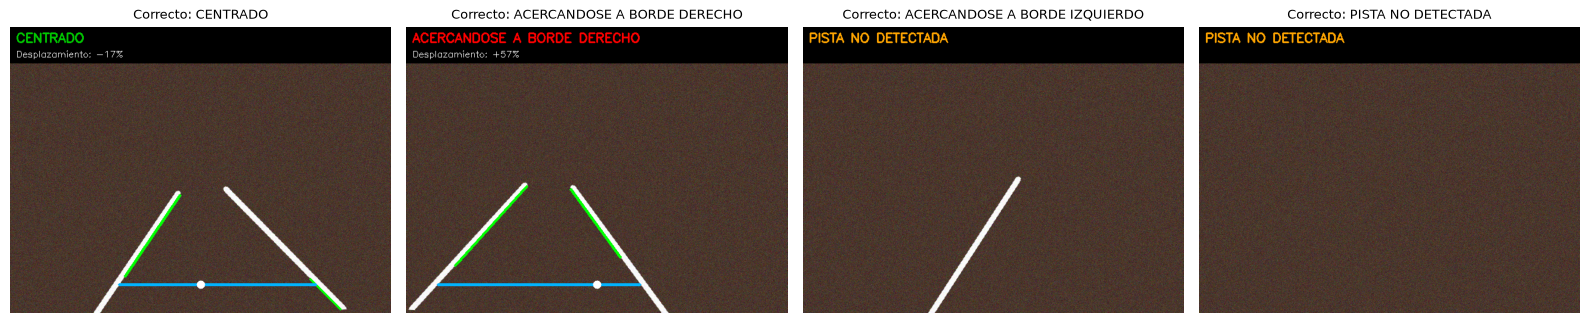

In [3]:
ETAPAS = [("CENTRADO", 0), ("ACERCANDOSE A BORDE DERECHO", -80),
          ("ACERCANDOSE A BORDE IZQUIERDO", 80), ("PISTA NO DETECTADA", None)]

def video_artificial(vibracion, n=200, semilla=0):
    """Devuelve una lista de (cuadro, respuesta_correcta)."""
    azar = np.random.default_rng(semilla)
    cuadros = []
    for i in range(n):
        respuesta, mover = ETAPAS[i * len(ETAPAS) // n]
        frame = np.full((480, 640, 3), (45, 55, 75), dtype=np.uint8)
        if mover is not None:
            for arriba, abajo in [(280, 100), (360, 540)]:
                if vibracion and azar.random() < 0.15 / 2:
                    continue  # línea tapada en este cuadro
                cv2.line(frame, (arriba + mover, 260), (abajo + mover, 479), (255, 255, 255), 8)
        if vibracion:
            angulo = 5 * np.sin(i * 0.7) + azar.normal(0, 1.5)   # balanceo del torso
            salto = 15 * np.sin(i * 1.4)                          # sube y baja al pisar
            giro = cv2.getRotationMatrix2D((320, 240), angulo, 1.0)
            giro[1, 2] += salto
            frame = cv2.warpAffine(frame, giro, (640, 480), borderValue=(45, 55, 75))
            ruido = azar.normal(0, 12, frame.shape)
            frame = np.clip(frame + ruido, 0, 255).astype(np.uint8)
        cuadros.append((frame, respuesta))
    return cuadros

def evaluar_artificial(cuadros, suavizador=None):
    filas = []
    for frame, respuesta in cuadros:
        desplazamiento, _, _ = detectar_carril(frame)
        if suavizador is not None:
            desplazamiento = suavizador(desplazamiento)
        filas.append({"correcta": respuesta, "detectada": estado_desde_desplazamiento(desplazamiento)})
    tabla = pd.DataFrame(filas)
    tabla["acierto"] = tabla["correcta"] == tabla["detectada"]
    return tabla

limpio = video_artificial(vibracion=False)
movido = video_artificial(vibracion=True)
res_limpio = evaluar_artificial(limpio)
res_movido = evaluar_artificial(movido)
print(f"Aciertos sin vibración: {res_limpio['acierto'].mean():.0%}")
print(f"Aciertos con vibración: {res_movido['acierto'].mean():.0%}")
print("\nAciertos por etapa (con vibración):")
print(res_movido.groupby("correcta", sort=False)["acierto"].mean().map("{:.0%}".format).to_string())

ejemplos = [movido[i] for i in (10, 60, 110, 160)]
mostrar([analizar_frame(f)[0] for f, _ in ejemplos], [f"Correcto: {r}" for _, r in ejemplos])

## 3. Suavizado entre cuadros (nuevo)

En la v1 cada cuadro se analiza por separado, así que un solo cuadro malo cambia la alerta. La idea más simple para corregirlo es **promediar los últimos cuadros**:

- Se guardan los últimos `VENTANA` desplazamientos (los cuadros sin detección cuentan como hueco).
- Si al menos la mitad tiene detección, se usa su promedio; si no, se reporta `PISTA NO DETECTADA`.

Tiene un costo: cuando de verdad te acercas a un borde, la alerta llega unos cuadros **más tarde**. Por eso se mide también el retraso.

In [4]:
VENTANA = 5  # cuadros que se promedian (a 25 fps, 5 cuadros = 0.2 s)

def crear_suavizador(ventana=VENTANA):
    historial = deque(maxlen=ventana)
    def suavizar(desplazamiento):
        historial.append(desplazamiento)
        validos = [d for d in historial if d is not None]
        if len(validos) * 2 < len(historial):
            return None
        return float(np.mean(validos))
    return suavizar

def cambios_de_estado(tabla):
    """Cuántas veces cambia la alerta (pocas = estable, muchas = parpadeo)."""
    return int((tabla["detectada"] != tabla["detectada"].shift()).sum() - 1)

def retraso_medio(tabla):
    """Cuadros que tarda la alerta en coincidir con la respuesta tras cada cambio de etapa."""
    retrasos = []
    for inicio in tabla.index[tabla["correcta"] != tabla["correcta"].shift()][1:]:
        tramo = tabla.loc[inicio:]
        tramo = tramo[tramo["correcta"] == tabla.loc[inicio, "correcta"]]
        primero = tramo.index[tramo["acierto"]]
        retrasos.append(primero[0] - inicio if len(primero) else len(tramo))
    return np.mean(retrasos)

comparacion = []
for nombre, cuadros in [("sin vibración", limpio), ("con vibración", movido)]:
    for metodo, suav in [("v1: cuadro por cuadro", None), (f"v2: promedio de {VENTANA}", crear_suavizador())]:
        t = evaluar_artificial(cuadros, suav)
        comparacion.append({"video": nombre, "método": metodo,
                            "aciertos": f"{t['acierto'].mean():.0%}",
                            "cambios de alerta (ideal = 3)": cambios_de_estado(t),
                            "retraso medio (cuadros)": round(retraso_medio(t), 1)})
pd.DataFrame(comparacion)

,video,método,aciertos,cambios de alerta (ideal = 3),retraso medio (cuadros)
0,sin vibración,v1: cuadro por cuadro,100%,3,0.0
1,sin vibración,v2: promedio de 5,96%,4,3.0
2,con vibración,v1: cuadro por cuadro,85%,54,0.0
3,con vibración,v2: promedio de 5,96%,6,2.3


## 4. Evaluación con imágenes reales anotadas (TrackAid-DT)

[TrackAid-DT](https://github.com/vrai-group/TrackAid-DT) (Narang et al., 2026, *Computer Vision and Image Understanding*, licencia **CC BY 4.0**) tiene 737 imágenes de pistas grabadas con cámara en el pecho de corredores, de día y de noche, cada una con el carril **marcado a mano**.

Con esa marca calculamos el desplazamiento "verdadero" a la misma altura y lo comparamos con el del detector. Así obtenemos números reales, que en la v1 no teníamos.

Detalles para que la comparación sea justa:
- El dataset trae 3 copias modificadas de cada foto (giro, ruido, desenfoque); usamos **una sola copia** por foto.
- Separamos por **video**: con unos videos se eligió el percentil de brillo (*ajuste*) y con los otros se reporta el resultado (*prueba*). Así no nos calificamos con las mismas fotos que usamos para ajustar.

In [5]:
import json, re, subprocess, random

# Se fija la versión exacta del dataset para que los resultados se puedan repetir.
TRACKAID_COMMIT = "aecdd7ad75c5d0f14c723c4a073568e6b7afa875"  # 17 de junio de 2026
if not Path("TrackAid-DT").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/vrai-group/TrackAid-DT"], check=True)
subprocess.run(["git", "-C", "TrackAid-DT", "checkout", "-q", TRACKAID_COMMIT], check=True)
version = subprocess.run(["git", "-C", "TrackAid-DT", "rev-parse", "HEAD"],
                         capture_output=True, text=True).stdout.strip()
print("Versión de TrackAid-DT:", version)
CARPETA = Path("TrackAid-DT/dataset/train")
coco = json.loads((CARPETA / "_annotations.coco.json").read_text())
anotacion = {a["image_id"]: a for a in coco["annotations"]}

# Una copia por foto original (orden alfabético = elección reproducible).
fotos, vistos = [], set()
for img in sorted(coco["images"], key=lambda x: x["file_name"]):
    original = img["extra"]["name"]
    if img["id"] in anotacion and original not in vistos:
        vistos.add(original)
        fotos.append(img)
print(f"Imágenes en el dataset: {len(coco['images'])} · fotos únicas con anotación: {len(fotos)}")

def desplazamiento_real(img, ancho_nuevo):
    """Desplazamiento según la marca hecha a mano, a la altura Y_REFERENCIA."""
    escala = ancho_nuevo / img["width"]
    alto_nuevo = int(img["height"] * escala)
    mascara = np.zeros((alto_nuevo, ancho_nuevo), np.uint8)
    for poligono in anotacion[img["id"]]["segmentation"]:
        puntos = (np.array(poligono).reshape(-1, 2) * escala).round().astype(np.int32)
        cv2.fillPoly(mascara, [puntos], 1)
    fila = np.where(mascara[int(alto_nuevo * Y_REFERENCIA)] > 0)[0]
    if len(fila) < 2:
        return None, mascara
    izq, der = fila.min(), fila.max()
    return (ancho_nuevo / 2 - (izq + der) / 2) / ((der - izq) / 2), mascara

def condicion(nombre):
    n = nombre.lower()
    if "notte" in n:
        return "noche"
    if n.startswith("video_giorno"):
        return "día · celular vertical"
    return "día · cámara en pecho"

filas = []
for img in fotos:
    foto = cv2.imread(str(CARPETA / img["file_name"]))
    foto = cv2.resize(foto, (640, int(foto.shape[0] * 640 / foto.shape[1])))
    real, _ = desplazamiento_real(img, 640)
    if real is None:
        continue  # la marca no llega a la altura de medición
    detectado, _, _ = detectar_carril(foto)
    filas.append({"foto": img["extra"]["name"], "archivo": img["file_name"],
                  "video": re.sub(r"-\d+\.jpg$", "", img["extra"]["name"]),
                  "condicion": condicion(img["extra"]["name"]),
                  "real": real, "detectado": detectado,
                  "estado_real": estado_desde_desplazamiento(real),
                  "estado_detectado": estado_desde_desplazamiento(detectado)})
reales = pd.DataFrame(filas)

# División por video: mitad ajuste, mitad prueba (semilla fija).
videos = sorted(reales["video"].unique())
random.Random(0).shuffle(videos)
reales["grupo"] = np.where(reales["video"].isin(videos[:len(videos) // 2]), "ajuste", "prueba")
reales.to_csv("resultados_trackaid.csv", index=False)
print(f"Fotos evaluables: {len(reales)} de {reales['video'].nunique()} videos · guardado en resultados_trackaid.csv")

Versión de TrackAid-DT: aecdd7ad75c5d0f14c723c4a073568e6b7afa875
Imágenes en el dataset: 746 · fotos únicas con anotación: 246


Fotos evaluables: 245 de 15 videos · guardado en resultados_trackaid.csv


In [6]:
def metricas(t):
    det = t[t["detectado"].notna()]
    correcto = det["estado_real"] == det["estado_detectado"]
    peligroso = (det["estado_real"] != "CENTRADO") & (det["estado_detectado"] == "CENTRADO")
    return pd.Series({
        "fotos": len(t),
        "carril detectado": f"{len(det) / len(t):.0%}",
        "estado correcto (de las detectadas)": f"{correcto.mean():.0%}",
        "estado correcto (del total)": f"{correcto.sum() / len(t):.0%}",
        "error mediano del desplazamiento": f"{(det['detectado'] - det['real']).abs().median():.2f}",
        "dice CENTRADO estando en borde": int(peligroso.sum()),
    })

print("Resultado en los videos de PRUEBA (no usados para ajustar):")
display(metricas(reales[reales["grupo"] == "prueba"]).to_frame("v2"))
print("Por condición de grabación (todas las fotos):")
display(reales.groupby("condicion").apply(metricas, include_groups=False))

Resultado en los videos de PRUEBA (no usados para ajustar):


,v2
fotos,172
carril detectado,77%
estado correcto (de las detectadas),89%
estado correcto (del total),69%
error mediano del desplazamiento,0.04
dice CENTRADO estando en borde,5


Por condición de grabación (todas las fotos):


,fotos,carril detectado,estado correcto (de las detectadas),estado correcto (del total),error mediano del desplazamiento,dice CENTRADO estando en borde
condicion,,,,,,
día · celular vertical,46,43%,70%,30%,0.14,1
día · cámara en pecho,124,94%,88%,83%,0.04,7
noche,75,64%,92%,59%,0.04,1


**Ejemplos.** En rojo, el carril marcado a mano; en verde, las líneas que encontró el detector. Se muestran aciertos y errores para entender **por qué** falla.

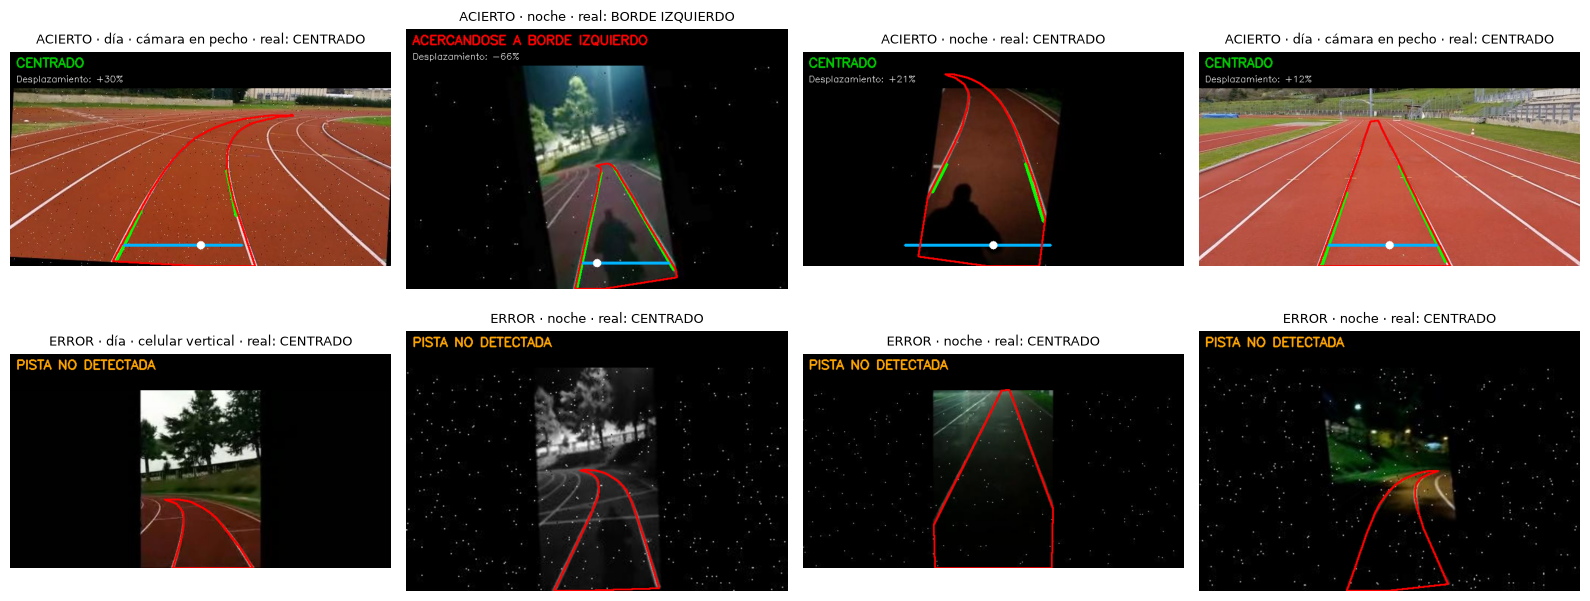

In [7]:
def ejemplo(fila):
    img = next(i for i in fotos if i["file_name"] == fila["archivo"])
    foto = cv2.imread(str(CARPETA / fila["archivo"]))
    foto = cv2.resize(foto, (640, int(foto.shape[0] * 640 / foto.shape[1])))
    _, mascara = desplazamiento_real(img, 640)
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    anotada = analizar_frame(foto)[0]
    cv2.drawContours(anotada, contornos, -1, (0, 0, 255), 2)
    marca = "ACIERTO" if fila["estado_real"] == fila["estado_detectado"] else "ERROR"
    return anotada, f"{marca} · {fila['condicion']} · real: {fila['estado_real'].replace('ACERCANDOSE A ', '')}"

azar = random.Random(3)
aciertos = reales[reales["estado_real"] == reales["estado_detectado"]]
errores = reales[reales["estado_real"] != reales["estado_detectado"]]
muestra = [aciertos.iloc[azar.randrange(len(aciertos))] for _ in range(4)] + \
          [errores.iloc[azar.randrange(len(errores))] for _ in range(4)]
imgs, titulos = zip(*[ejemplo(f) for f in muestra])
mostrar(list(imgs), list(titulos))

## 5. (Opcional) Prueba con tu propio video

Graba desde el centro del torso, apuntando hacia adelante y un poco hacia el suelo, con las dos líneas visibles. Empieza **caminando, acompañado y en una zona controlada**. No grabes a otras personas sin su consentimiento.

En Colab se abre un botón para subir el archivo. Fuera de Colab, escribe la ruta en `VIDEO`.

In [8]:
VIDEO = None  # Fuera de Colab: VIDEO = "mi_video.mp4"
if VIDEO is None:
    try:
        from google.colab import files
        subidos = files.upload()
        VIDEO = next(iter(subidos)) if subidos else None
    except ImportError:
        print("No estás en Colab: escribe la ruta en VIDEO y vuelve a ejecutar.")
print("Video:", VIDEO)

No estás en Colab: escribe la ruta en VIDEO y vuelve a ejecutar.
Video: None


In [9]:
if VIDEO:
    cap = cv2.VideoCapture(VIDEO)
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    w0, h0 = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    factor = min(1.0, 960 / w0)
    w, h = int(w0 * factor) // 2 * 2, int(h0 * factor) // 2 * 2
    escritor = cv2.VideoWriter("temporal.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    suavizar = crear_suavizador()
    registro = []
    while True:
        ok, cuadro = cap.read()
        if not ok:
            break
        cuadro = cv2.resize(cuadro, (w, h))
        crudo, izq, der = detectar_carril(cuadro)
        suave = suavizar(crudo)
        escritor.write(dibujar(cuadro, suave, izq, der, "(suavizado)"))
        registro.append({"cuadro": len(registro), "segundo": round(len(registro) / fps, 2),
                         "desplazamiento_crudo": crudo, "desplazamiento_suavizado": suave,
                         "estado": estado_desde_desplazamiento(suave)})
    cap.release()
    escritor.release()
    registro = pd.DataFrame(registro)
    registro.to_csv("registro_video.csv", index=False)
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "temporal.mp4", "-vcodec", "libx264",
                    "-pix_fmt", "yuv420p", "resultado_carril.mp4"], check=True)
    print(registro["estado"].value_counts().to_string())
    from IPython.display import Video
    display(Video("resultado_carril.mp4", embed=True))

## 6. Cómo leer los resultados y siguientes pasos

- **Carril detectado** bajo = el sistema se queda callado (`PISTA NO DETECTADA`). Es molesto pero no peligroso.
- **"Dice CENTRADO estando en borde"** es el error **más peligroso**: el atleta cree que va bien y no es así. Es la métrica que más hay que bajar.
- El umbral de 30 % es un punto de partida, **no** una distancia segura validada.

**Limitaciones que siguen abiertas:** curvas (el detector busca líneas rectas), carriles vecinos, sombras, cámara inclinada. Las imágenes de TrackAid-DT son fotos sueltas, no videos continuos, así que el suavizado solo se probó con el video artificial.

**Siguientes pasos sugeridos (en orden):**
1. Grabar videos propios cortos (acompañado) y anotar a mano en qué segundos te acercas a cada borde.
2. Medir con esos videos el retraso real de la alerta con y sin suavizado.
3. Si la detección clásica no mejora en curvas y de noche, probar un modelo de segmentación ya entrenado con TrackAid-DT.